In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import astropy.units as u
import numpy as np
import gc
import lsst.daf.butler as DafButler
import lsst.summit.utils.plotting as splot
import PIL
from astropy.coordinates import SkyCoord
import lsst.afw.display as afwDisplay
from lsst.pipe.tasks.visualizeVisit import (
    VisualizeBinExpConfig,
    VisualizeBinExpTask,
    VisualizeMosaicExpConfig,
    VisualizeMosaicExpTask,
)

from lsst.summit.utils.utils import getCameraFromInstrumentName
from photutils.segmentation import detect_sources, detect_threshold
from photutils.utils import circular_footprint
from astropy.convolution import convolve
from photutils.segmentation import make_2dgaussian_kernel 
from astropy.visualization import SqrtStretch, LogStretch
from astropy.visualization.mpl_normalize import ImageNormalize

from astropy.stats import SigmaClip

from photutils.background import Background2D, MedianBackground

%matplotlib inline
%matplotlib widget




In [2]:
def bin_image(image, camera, binning=8):
    visualizeBinExpConfig = VisualizeBinExpConfig()
    visualizeBinExpConfig.binning = binning
    visualizeBinExpTask = VisualizeBinExpTask(config=visualizeBinExpConfig)
    return visualizeBinExpTask.run(inputExp=image, camera=camera).outputExp

def doStarless(img):
    kernel = make_2dgaussian_kernel(5, size=3)   
    threshold = detect_threshold(img, 3.)
    segment_map = detect_sources(img, threshold, npixels=1)
    
    footprint = circular_footprint(radius=3)
    dilateMask = segment_map.make_source_mask(footprint=footprint)
    dilateAndSmoothMask = convolve(dilateMask, kernel)

    starlessImg = np.where(dilateAndSmoothMask != 0,np.median(img), img)
    return starlessImg

def remove_stars_from_mosaic(mosaic_img):
    # Handle NaNs and infs by masking them
    img = np.array(mosaic_img, dtype=np.float32)
    mask = ~np.isfinite(img)
    # Replace NaNs/Infs with median of finite values
    finite_median = np.mean(img[~mask])
    img[mask] = finite_median

    # Run star removal
    starless = doStarless(img,finite_median)

    # Restore NaNs/Infs to their original positions
    starless[mask] = np.nan
    return starless

In [3]:
#Collections=['LSSTComCam/runs/nightlyValidation']
butler = DafButler.Butler('embargo', collections=["LSSTCam/runs/nightlyValidation",'u/ataranto/lsst_outputs'], instrument='LSSTCam')
registry = butler.registry
camera = getCameraFromInstrumentName("LSSTCam")

In [4]:
plt.close('all')
def so_deg(val):
    return (float(val)*u.rad).to(u.deg).value

In [ ]:
day_obs=20250515
frames=[]
al_hms='14h39m36.495s'
al_dms='-60d50m2.3s'
alpha = SkyCoord(ra=al_hms, dec=al_dms, unit=(u.hourangle, u.deg), frame='icrs')

print(alpha.ra.deg)
#alpha = SkyCoord(ra=ra_alp*u.deg, dec=dec_alp*u.deg, frame='icrs')
print(alpha.dec.deg)



Dref_uns = list(registry.queryDatasets('post_isr_image', where=f"visit={2025051500393} and detector=94"))  #corner dtectors 188, 161, 65, 20, 0, 27, 123, 168
Dref=sorted( Dref_uns, key = lambda x : x.dataId['detector'] )
dataImgs = [butler.get(dr) for dr in Dref]
wcs = dataImgs[0].wcs #.getFitsMetadata().items()
hold=wcs
for seq in range(394,467,6):
    plt.close('all')
    visit=day_obs*100000+seq
    print('visit   ',visit)
    #  (151..161,111..116,107,146,149,103,104,106,145,148)
    Dref_uns = list(registry.queryDatasets('post_isr_image', where=f"visit={visit} and detector in (153)"))  #corner dtectors 188, 161, 65, 20, 0, 27, 123, 168
    Dref=sorted( Dref_uns, key = lambda x : x.dataId['detector'] )
    exposures = [butler.get(dr) for dr in Dref]
    wcs = exposures[0].wcs #.getFitsMetadata().items()
    center_ra, center_dec = wcs.getSkyOrigin()
    center = SkyCoord(ra=so_deg(center_ra)*u.deg, dec=so_deg(center_dec)*u.deg, frame='icrs')
    print(center.to_string('hmsdms'))
    print('alpha cen off axis:   ', alpha.separation(center).deg, 'deg ///   ',alpha.separation(center).deg*3600.0, ' arcsec ' )
    print('-----------------')
 
    # sigma_clip = SigmaClip(sigma=3.0)
    # bkg_estimator = MedianBackground()
    # binning = 4
    # exposures_binned = [bin_image(exposure, camera, binning) for exposure in exposures]

    # for i, exp in enumerate(exposures_binned):    # 
    #     bkg = Background2D(exp.image.array, (70, 70), filter_size=(3, 3), sigma_clip=sigma_clip) #, bkg_estimator=bkg_estimator)
    #     starlessImg = doStarless(exp.image.array-bkg.background)
    #     exp.image.array = starlessImg
    #     exposures_binned[i] = exp
    
    visualizeMosaicExpConfig = VisualizeMosaicExpConfig()
    visualizeMosaicExpConfig.binning = binning
    visualizeMosaicExpTask = VisualizeMosaicExpTask(config=visualizeMosaicExpConfig)
    mosaic = visualizeMosaicExpTask.run(inputExps=exposures_binned, camera=camera).outputData   
 
    # fig=splot.plot(mosaic.array, stretch='log',percentile=98,cmap='plasma')    
    # ax=fig.get_axes()
    # ax[0].set_title('Raft 34 ', fontsize=20, fontweight='bold')
    # # ax[0].annotate(
    # #     f"Off axis  {alpha.separation(center).deg:.5f}  deg",
    # #     xy=(0.5, 0.15),
    # #     xycoords='axes fraction',
    # #     ha='center',
    # #     fontsize=20,
    # #     color='white',
    # #     fontweight='bold'
    # # )
    # # Get the non-nan indices
    # non_nan_indices = np.argwhere(~np.isnan(mosaic.array))
    # if non_nan_indices.size > 0:
    #     y_min, x_min = non_nan_indices.min(axis=0)
    #     y_max, x_max = non_nan_indices.max(axis=0)
    #     ax[0].set_xlim(x_min, x_max)
    #     ax[0].set_ylim(y_min, y_max)
    # plt.tight_layout()

    # plt.savefig(f"long_tail_{visit}.png")
    # plt.show()
    # # plt.close()
    hold=wcs
    # break
    




219.9020625
-60.83397222222222
visit    2025051500394
14h49m53.58122134s -59d18m53.76294174s
alpha cen off axis:    1.987869201494097 deg ///    7156.329125378749  arcsec 
-----------------
visit    2025051500400
14h49m57.71761932s -59d18m50.9433668s
alpha cen off axis:    1.9940299609061545 deg ///    7178.507859262156  arcsec 
-----------------
visit    2025051500406
14h50m01.90527407s -59d18m48.23094251s
alpha cen off axis:    2.0002554083470496 deg ///    7200.919470049379  arcsec 
-----------------
visit    2025051500412
14h50m06.06539469s -59d18m46.39628001s
alpha cen off axis:    2.0062745490563194 deg ///    7222.58837660275  arcsec 
-----------------
visit    2025051500418
14h50m10.2214865s -59d18m44.68241101s
alpha cen off axis:    2.012281818592764 deg ///    7244.21454693395  arcsec 
-----------------
visit    2025051500424
14h50m14.3982299s -59d18m43.84011896s
alpha cen off axis:    2.018150906351075 deg ///    7265.34326286387  arcsec 
-----------------
visit    202505150

In [29]:
np.hypot(15486-12812,12602- 9850)*0.8/3600.0


np.float64(0.8527017338516325)

In [6]:
from PIL import Image

# Settings
rows, cols = 3, 4
image_paths = [f"wing_visit{visit}.png" for visit in range(2025051500393,2025051500467,6)]
# image_paths.append("wing_visit2025051500402.png")
image_paths.sort()
images = [Image.open(path) for path in image_paths]

# Get size of individual image (assumes all same size)
img_width, img_height = images[0].size

# Create new blank image
mosaic = Image.new('RGB', (cols * img_width, rows * img_height))

# Paste images in order
for index, img in enumerate(images):
    row = index // cols
    col = index % cols
    mosaic.paste(img, (col * img_width, row * img_height))

# Save or show
mosaic.save("mosaic.jpg")
# mosaic.show()

219.9020625
-60.83397222222222
visit    2025051300362
alpha cen off axis:    1.767023969233267 deg ///    6361.286289239762  arcsec 
-----------------


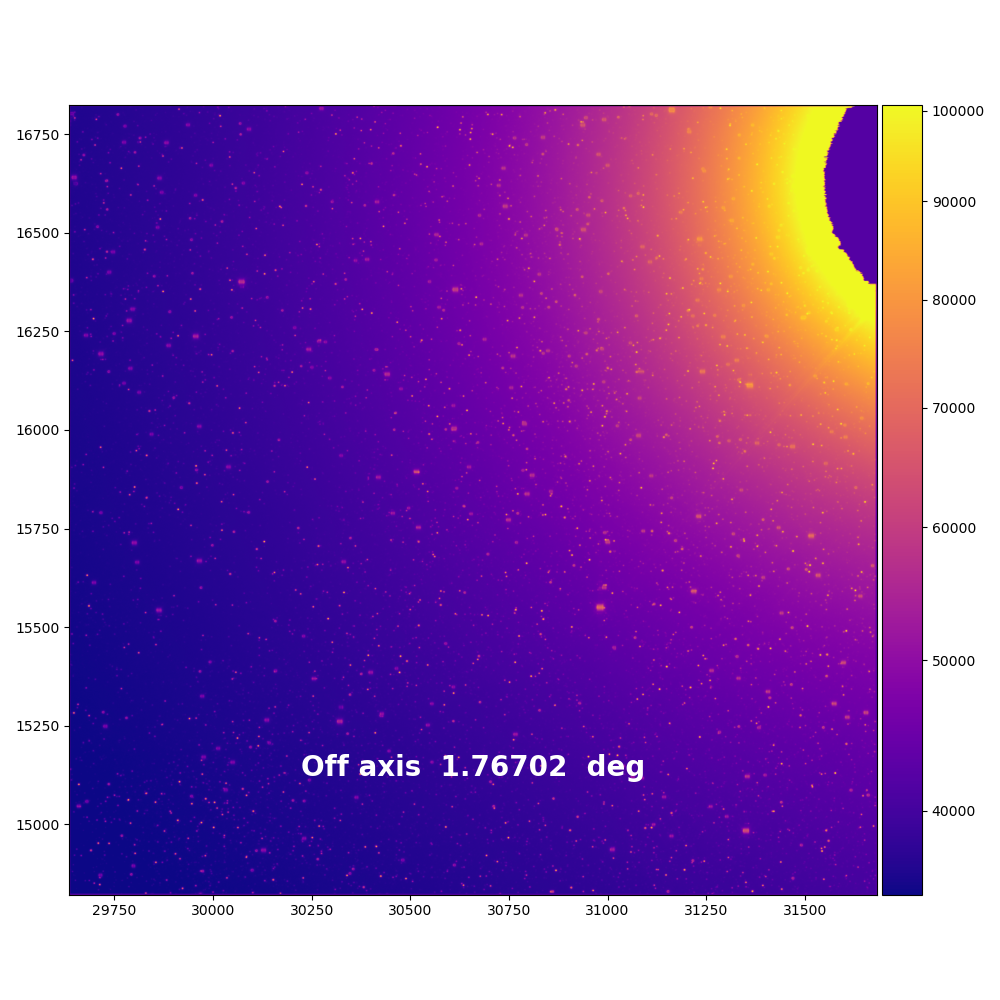

visit    2025051300363
alpha cen off axis:    1.783910986040947 deg ///    6422.079549747409  arcsec 
-----------------


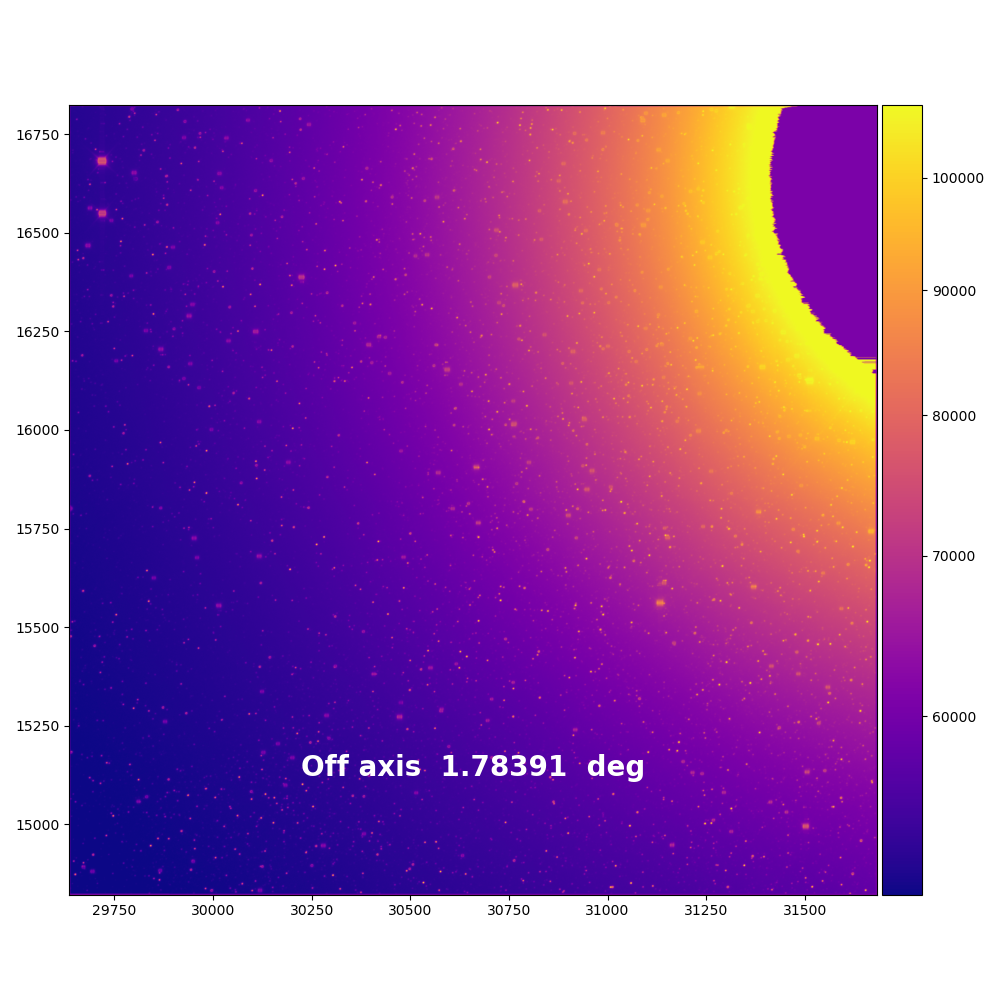

visit    2025051300364
alpha cen off axis:    1.8009050920873106 deg ///    6483.258331514318  arcsec 
-----------------


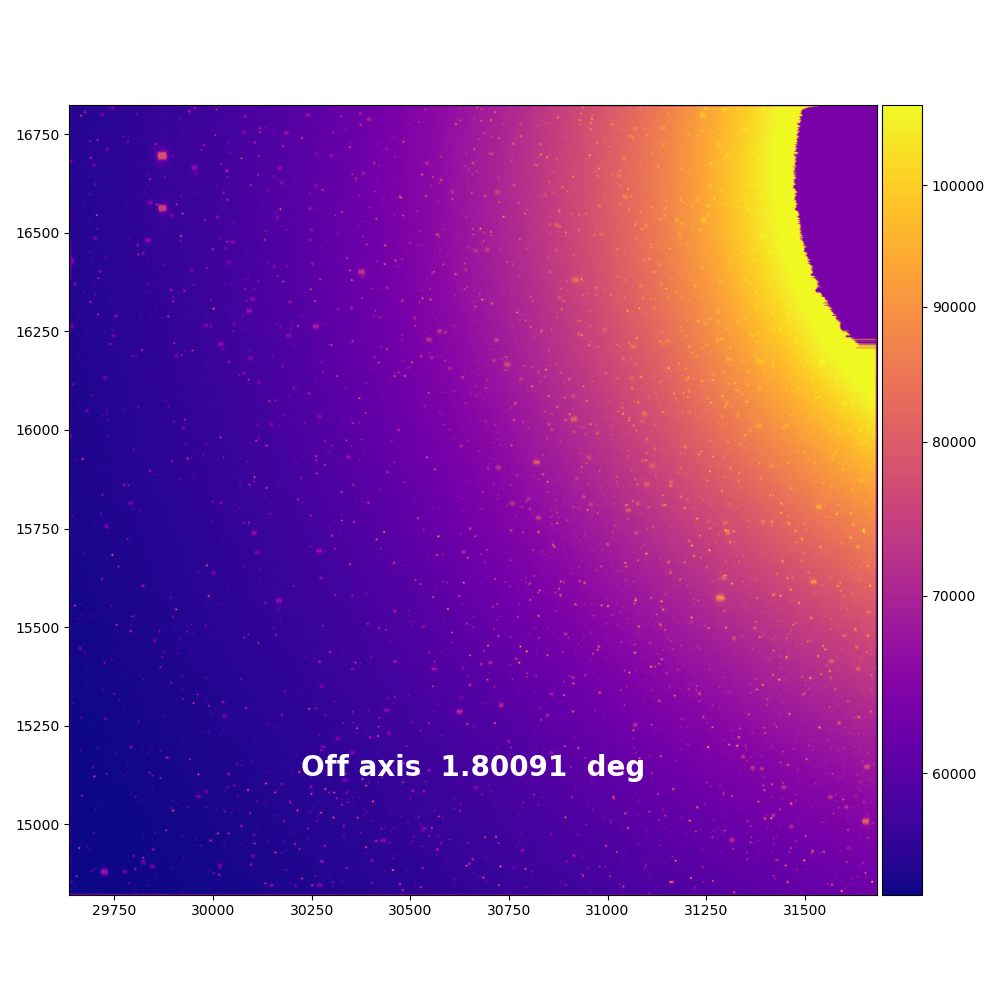

visit    2025051300365
alpha cen off axis:    1.8178021304945742 deg ///    6544.087669780467  arcsec 
-----------------


In [ ]:
day_obs=20250513
frames=[]
al_hms='14h39m36.495s'
al_dms='-60d50m2.3s'
alpha = SkyCoord(ra=al_hms, dec=al_dms, unit=(u.hourangle, u.deg), frame='icrs')

print(alpha.ra.deg)
#alpha = SkyCoord(ra=ra_alp*u.deg, dec=dec_alp*u.deg, frame='icrs')
print(alpha.dec.deg)



Dref_uns = list(registry.queryDatasets('post_isr_image', where=f"visit={2025051500393} and detector=94"))  #corner dtectors 188, 161, 65, 20, 0, 27, 123, 168
Dref=sorted( Dref_uns, key = lambda x : x.dataId['detector'] )
dataImgs = [butler.get(dr) for dr in Dref]
wcs = dataImgs[0].wcs #.getFitsMetadata().items()
hold=wcs
for seq in range(362,405):
    plt.close('all')
    visit=day_obs*100000+seq
    print('visit   ',visit)
    #  (151..161,111..116,107,146,149,103,104,106,145,148)
    Dref_uns = list(registry.queryDatasets('post_isr_image', where=f"visit={visit} and detector=113"))  #corner dtectors 188, 161, 65, 20, 0, 27, 123, 168
    Dref=sorted( Dref_uns, key = lambda x : x.dataId['detector'] )
    exposures = [butler.get(dr) for dr in Dref]
    wcs = exposures[0].wcs #.getFitsMetadata().items()
    center_ra, center_dec = wcs.getSkyOrigin()
    center = SkyCoord(ra=so_deg(center_ra)*u.deg, dec=so_deg(center_dec)*u.deg, frame='icrs')
  
    print('alpha cen off axis:   ', alpha.separation(center).deg, 'deg ///   ',alpha.separation(center).deg*3600.0, ' arcsec ' )
    print('-----------------')
 
    sigma_clip = SigmaClip(sigma=3.0)
    bkg_estimator = MedianBackground()
    binning = 2
    exposures_binned = [bin_image(exposure, camera, binning) for exposure in exposures]

    # for i, exp in enumerate(exposures_binned):    # 
    #     bkg = Background2D(exp.image.array, (70, 70), filter_size=(3, 3), sigma_clip=sigma_clip) #, bkg_estimator=bkg_estimator)
    #     starlessImg = doStarless(exp.image.array-bkg.background)
    #     exp.image.array = starlessImg
    #     exposures_binned[i] = exp
    
    visualizeMosaicExpConfig = VisualizeMosaicExpConfig()
    visualizeMosaicExpConfig.binning = binning
    visualizeMosaicExpTask = VisualizeMosaicExpTask(config=visualizeMosaicExpConfig)
    mosaic = visualizeMosaicExpTask.run(inputExps=exposures_binned, camera=camera).outputData   
 
    fig=splot.plot(mosaic.array, stretch='log',percentile=98,cmap='plasma')    
    ax=fig.get_axes()
    ax[0].annotate(
        f"Off axis  {alpha.separation(center).deg:.5f}  deg",
        xy=(0.5, 0.15),
        xycoords='axes fraction',
        ha='center',
        fontsize=20,
        color='white',
        fontweight='bold'
    )
    # Get the non-nan indices
    non_nan_indices = np.argwhere(~np.isnan(mosaic.array))
    if non_nan_indices.size > 0:
        y_min, x_min = non_nan_indices.min(axis=0)
        y_max, x_max = non_nan_indices.max(axis=0)
        ax[0].set_xlim(x_min, x_max)
        ax[0].set_ylim(y_min, y_max)
    plt.tight_layout()

    # plt.savefig(f"wing_visit{visit}.png")
    plt.show()
    plt.close()
    hold=wcs
    




In [6]:
plt.savefig('mosaic_20250515.png', dpi=300, bbox_inches='tight')


<Figure size 640x480 with 0 Axes>

In [ ]:
image0=dataImgs[0]
wcs=image0.getWcs()
wcs

In [ ]:
wcs1 = dataImgs[im].wcs #.getFitsMetadata().items()
ra_so1, dec_so1=wcs1.getSkyOrigin()
so_ra_deg=(float(ra_so1)* u.rad).to(u.deg).value
so_dec_deg=(float(dec_so1)* u.rad).to(u.deg).value
print('fov center    ', (float(ra_so1)* u.rad).to(u.deg).value, (float(dec_so1)* u.rad).to(u.deg).value)
rom_ra1, rom_dec1 = wcs1.pixelToSky(3200, 863)
rom_ra_deg=(float(rom_ra1)* u.rad).to(u.deg).value
rom_dec_deg=(float(rom_dec1)* u.rad).to(u.deg).value
print('star position ',rom_ra_deg, rom_dec_deg)

print(ra_so1)

In [ ]:
#wcs0 = dataImgs[0].wcs #.getFitsMetadata().items()
#ra_so0, dec_so0=wcs0.getSkyOrigin()
#print('fov center', (float(ra_so0)* u.rad).to(u.deg).value, (float(dec_so0)* u.rad).to(u.deg).value)
#rom_ra0, rom_dec0 = wcs0.pixelToSky(200, 3400)
#print(' star pos ', (float(rom_ra0)* u.rad).to(u.deg).value, (float(rom_dec0)* u.rad).to(u.deg).value)

In [ ]:
from astropy.coordinates import SkyCoord

# Create SkyCoord objects for the two points
#coord_so0 = SkyCoord(ra=so_ra_deg0, dec=so_dec_deg0, frame='icrs')
#coord_rom0 = SkyCoord(ra=rom_ra_deg0, dec=rom_dec_deg0, frame='icrs')
coord_so1 = SkyCoord(ra=float(ra_so1)*u.rad, dec=float(dec_so1)*u.rad, frame='icrs')
coord_rom1 = SkyCoord(ra=float(rom_ra1)*u.rad, dec=float(rom_dec1)*u.rad, frame='icrs')

# Compute the angular separation
#distance0 = coord_so0.separation(coord_rom0)

distance1 = coord_so1.separation(coord_rom1)

#print(f"Distance: {distance0.deg} degrees")

print(f"Distance: {distance1.deg} degrees")


309.418960393311
21.12980589486759 10.162267829723913
(41.851610197088014, -357.5673501962232)


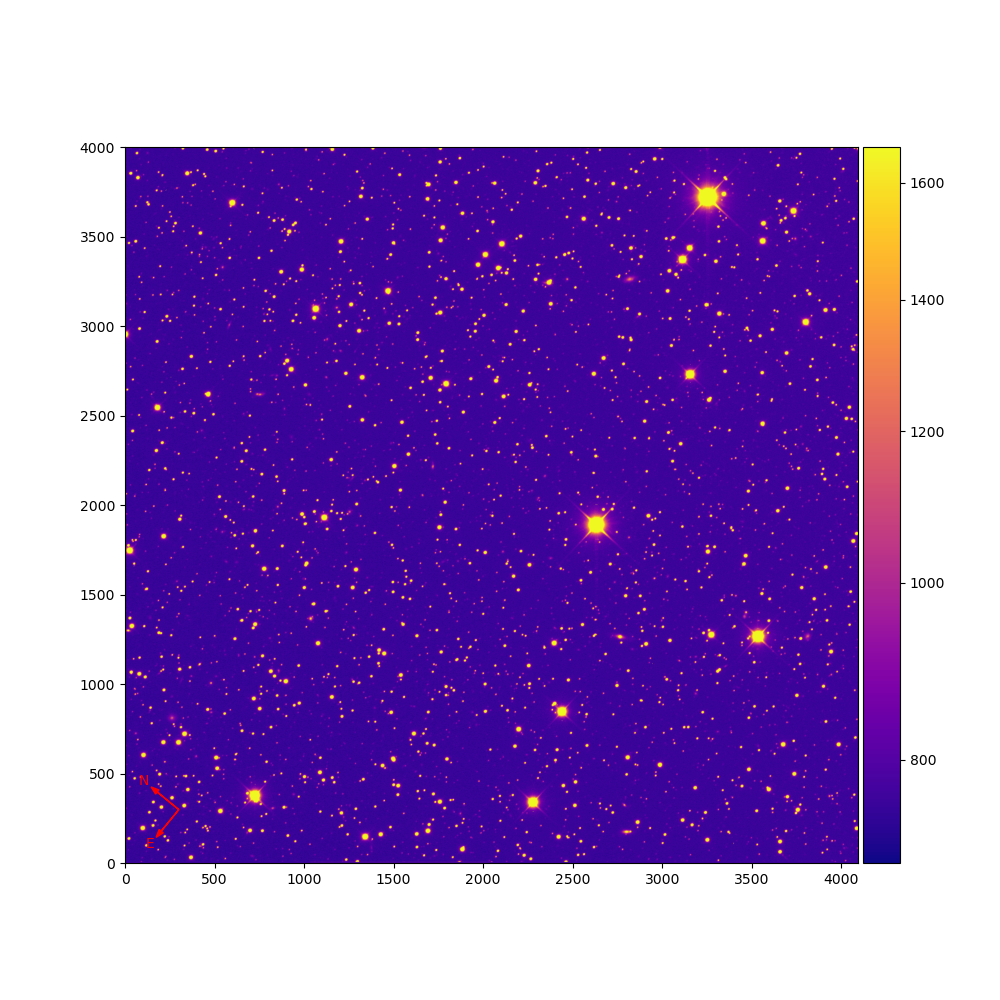

In [18]:
from astropy.coordinates import SkyCoord
import astropy.units as u

butler = DafButler.Butler('embargo', collections=['u/ataranto/lsst_outputs'], instrument='LSSTCam')
registry = butler.registry
camera = getCameraFromInstrumentName("LSSTCam")
day_obs=20250515

Dref= list(registry.queryDatasets('post_isr_image', where=f"visit={2025050500421} and detector = 94"))  #corner dtectors 188, 161, 65, 20, 0, 27, 123, 168
exposures = [butler.get(dr) for dr in Dref]
splot.plot(exposures[0], stretch='log',percentile=98,cmap='plasma')    

image=exposures[0]
header = {key: val for key, val in image.getMetadata().items()}
ra,dec=header['RA'], header['DEC']
print(header['ROTPA'])

center = SkyCoord(ra='14h58m38s', dec='-39d54m35s', unit=(u.hourangle, u.deg), frame='icrs')

al_hms='14h39m36.495s'
al_dms= '-60d50m2.3s'
alpha = SkyCoord(ra=al_hms, dec=al_dms, unit=(u.hourangle, u.deg), frame='icrs')
sep = alpha.separation(center).deg
rot = alpha.position_angle(center).deg 

print(sep,rot)

def get_q_rtp(butler, visit):
    visitInfo = butler.get("raw.visitInfo", exposure=visit, detector=94)
    parAngle = visitInfo.boresightParAngle.asDegrees()
    rotAngle = visitInfo.boresightRotAngle.asDegrees()
    return parAngle, parAngle - rotAngle - 90.0

print(get_q_rtp(butler, 2025050500421))


def get_alt_ha(target, center, loc, tobs):
    
    d = target.separation(center).deg
    target_altaz = convert_radec_to_altaz(loc, tobs, target)
    center_altaz = convert_radec_to_altaz(loc, tobs, center)
    
    delta_alt = center_altaz.alt.deg - target_altaz.alt.deg 
    return np.rad2deg(np.asin(delta_alt / d))


    

In [1]:
print(list(header.keys()))

NameError: name 'header' is not defined

In [27]:
#sen -1 (delta alt / dist )


    
delta_alt = 
print( np.rad2deg(np.asin(delta_alt / d)))
    


NameError: name 'convert_radec_to_altaz' is not defined